# 00 - The ideal interlaced dataset

Everything in the 00 block consumes what this notebook writes. The scientific choices are
made here and nowhere else.

## The geometry

| quantity | value | origin |
|---|---|---|
| accelerating voltage | **60 kV** | chosen: more phase per atom, less damage |
| convergence semi-angle | 30.0 mrad | Pari |
| defocus $C_{10}$ | $+100\ \mathrm{\AA}$ = 10 nm | chosen |
| scan step | $0.15\ \mathrm{\AA}$ | matches `04 - direct methods - multiplex SSB.ipynb` |
| scan extent | 30 Å, $200^2$ positions | covers the 9 Å excitation with margin |
| collection angle | 52.47 mrad | ARINA edge, 52.5 mrad |
| detector | $192\times192$ at 0.54657 mrad/px | ARINA, no binning needed |
| simulation cell | $89.029\ \mathrm{\AA}$, $900^2$ px | ours |

**Why 60 kV.** The specimen is two-dimensional, so penetration is not a constraint, and a
slower electron interacts more strongly: the interaction parameter rises from
$\sigma = 6.53\times10^{-4}$ at 300 kV to $1.14\times10^{-3}$ at 60 kV, a factor **1.74**
more phase for the same projected potential, at lower knock-on damage.

It also fixes a provenance problem. The stored hBN phase arrays carry no energy metadata,
but the companion notebook that generated the reference figures divides them by
$\sigma(60\ \mathrm{keV})$ and is annotated `# if acc is 60e3`. They are 60 keV phases.
Running them at 300 kV, as earlier versions of this notebook did, used them at an energy
they were not computed for.

And it halves the aberration problem. The defocus phase at the aperture edge,
$\chi_{\max} = \pi C_{10}\alpha^2/\lambda$, falls from $4.57\pi$ at 300 kV to
$1.85\pi$ at 60 kV for the same $C_{10}$.

**Why the step is 0.15 Å and not $\lambda/4\alpha$.** At 60 kV the probe bandwidth is
$2\alpha/\lambda = 1.233\ \mathrm{\AA^{-1}}$ and the textbook alias-free step is
$\lambda/4\alpha = 0.4055\ \mathrm{\AA}$ - but that is the *marginal* condition, putting
the scan Nyquist exactly at the bandwidth so the baseband's own tail reaches the
interlacing carrier with no gap between them. Notebook 03 showed this matters for the
direct methods. $0.15\ \mathrm{\AA}$ oversamples by **2.70x**, which is what the reference
notebook uses, and leaves the carrier in clean empty frequency.

**Why the cell is 89.029 Å.** The diffraction-plane pitch of a simulation is $\lambda/L$,
so ARINA's 0.54657 mrad/px is an exact bin of it only on the ladder
$L = 89.029\,B\ \mathrm{\AA}$. At 60 kV $B = 1$ already works - the simulated pitch *is*
ARINA's, with no binning at all - and the cell clears the scan plus the probe's 99% tail
by 18 Å. $N = 900$ keeps $dx = 0.0989\ \mathrm{\AA}$ and the antialias cutoff at 164 mrad
against a 52.47 mrad collection angle.

## What it writes

| file | contents |
|---|---|
| `data/ideal_geometry.json` | **all metadata, human-readable**, indent 2 |
| `data/ideal_truth.npz` | the four ground-truth phase images |
| `data/ideal_merged_dose_{inf,1e6,1e5}.npy` | $200^2\times192^2$ float32, 5.90 GB each |

The scan mask, scan positions and object axis are derivable from the JSON in two lines
each, so they are described there rather than duplicated into an array file.

In [1]:
import json
import pickle
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from scipy.ndimage import map_coordinates

import abtem
from abtem.core.energy import energy2sigma
from abtem.potentials.iam import PotentialArray
from abtem.scan import CustomScan

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
PHASE_DIR = NOTEBOOK_DIR.parent / "hbn_bcenters_data"
sys.path.insert(0, str(NOTEBOOK_DIR.parent))

# Virtual imaging is quanTEM's job, not this notebook's.
import method_wrappers
from quantem.core.datastructures import Dataset4dstem
from quantem.core.utils.diffractive_imaging_utils import fit_probe_circle

try:
    import cupy
    abtem.config.set({"device": "gpu"})
    ABTEM_DEVICE = "gpu"
    print("abtem", abtem.__version__, "on gpu via cupy", cupy.__version__,
          "-", cupy.cuda.runtime.getDeviceProperties(0)["name"].decode())
except Exception as exc:
    abtem.config.set({"device": "cpu"})
    ABTEM_DEVICE = "cpu"
    print(f"abtem {abtem.__version__} on CPU - cupy unavailable ({exc}).")


def to_numpy(array):
    """abTEM hands back CuPy arrays on the GPU; numpy refuses to convert them implicitly."""
    return array.get() if hasattr(array, "get") else np.asarray(array)


print("phases :", PHASE_DIR)
print("out    :", DATA_DIR)

cuda:0
abtem 1.0.10 on gpu via cupy 14.2.0 - NVIDIA GeForce RTX 5090
phases : /home/rotem/ptycho_light/quantem/scripts/hbn_bcenters_data
out    : /home/rotem/ptycho_light/quantem/scripts/time_dependent_noise/data


In [2]:
# --- beam and camera, from Pari -------------------------------------------------
ACC_VOLTAGE_EV        = 60e3       # 2D specimen: no penetration limit, and 1.74x the
                                   # phase of 300 kV for the same projected potential
PROBE_SEMIANGLE_MRAD  = 30.0
PROBE_DEFOCUS_ANG     = 100.0      # 10 nm, quantEM/abTEM sign
ARINA_PITCH_MRAD      = 0.54657
ARINA_HALF_ANGLE_MRAD = 52.5

# --- the simulation cell ----------------------------------------------------------
CELL_EXTENT_ANG     = 89.029       # = 89.029 * DETECTOR_BIN, for an exact bin
N_OBJECT_PX         = 900          # 5-smooth; dx ~ 0.099 A, antialias 164 mrad
DETECTOR_BIN        = 1            # at 60 kV the simulated pitch IS ARINA's
SLICE_THICKNESS_ANG = 1.0

# --- the scan: one configuration --------------------------------------------------
# lambda/4alpha = 0.4055 A is only the MARGINAL alias-free step; 0.15 A oversamples the
# probe bandwidth 2.70x and matches "04 - direct methods - multiplex SSB.ipynb".
SCAN_STEP_ANG   = 0.15
SCAN_EXTENT_ANG = 30.0

# --- the excitation, as isolated in hbn_bcenters_data -----------------------------
TAPER_INNER_ANG, TAPER_OUTER_ANG = 6.0, 9.0
A_HBN, N_HBN_CELLS = 2.506, 6

# --- doses, electrons per square Angstrom ------------------------------------------
DOSES = {"inf": None, "1e6": 1e6, "1e5": 1e5}

# --- compute ------------------------------------------------------------------------
SCAN_CHUNK = 1024

# No fixed RNG seed anywhere in this pipeline. A pinned seed means every run sees the
# same single noise realisation, and a number read off one realisation can look
# consistently good when it was only ever sampled once. Each run is an independent draw.

OBJECT_DX_ANG = CELL_EXTENT_ANG / N_OBJECT_PX
N_SCAN = int(np.floor(SCAN_EXTENT_ANG / SCAN_STEP_ANG))

print(f"object : {N_OBJECT_PX}^2 px, {OBJECT_DX_ANG:.6f} A/px, {CELL_EXTENT_ANG} A cell")
print(f"scan   : {N_SCAN}^2 = {N_SCAN**2:,} positions at {SCAN_STEP_ANG} A "
      f"over {SCAN_EXTENT_ANG} A")
assert abs(CELL_EXTENT_ANG - 89.029 * DETECTOR_BIN) < 0.05, \
    "cell and bin are inconsistent; the binned pitch will not be ARINA's"

object : 900^2 px, 0.098921 A/px, 89.029 A cell
scan   : 200^2 = 40,000 positions at 0.15 A over 30.0 A


In [3]:
probe = abtem.Probe(
    energy=ACC_VOLTAGE_EV,
    semiangle_cutoff=PROBE_SEMIANGLE_MRAD,
    defocus=PROBE_DEFOCUS_ANG,
    extent=CELL_EXTENT_ANG,
    gpts=N_OBJECT_PX,
)
wavelength_ang = float(probe.wavelength)
DETECTOR_PITCH_MRAD = wavelength_ang / CELL_EXTENT_ANG * 1e3
binned_pitch_mrad = DETECTOR_PITCH_MRAD * DETECTOR_BIN

n_detector_binned = int(round(2 * ARINA_HALF_ANGLE_MRAD / binned_pitch_mrad))
n_detector_native = n_detector_binned * DETECTOR_BIN
crop_half_angle_mrad = n_detector_native / 2 * DETECTOR_PITCH_MRAD
antialias_mrad = float(probe.cutoff_angles[0])
SCAN_ORIGIN_OFFSET_ANG = (N_OBJECT_PX // 2) * OBJECT_DX_ANG

_built = to_numpy(probe.build(
    scan=[(SCAN_ORIGIN_OFFSET_ANG, SCAN_ORIGIN_OFFSET_ANG)]).compute().array)
probe_at_centre = _built if _built.ndim == 2 else _built[0]
probe_intensity = np.abs(probe_at_centre) ** 2
peak_i, peak_j = np.unravel_index(probe_intensity.argmax(), probe_intensity.shape)
rad = np.hypot((np.arange(N_OBJECT_PX)[:, None] - peak_i) * OBJECT_DX_ANG,
               (np.arange(N_OBJECT_PX)[None, :] - peak_j) * OBJECT_DX_ANG)
order = np.argsort(rad.ravel())
cumulative = np.cumsum(probe_intensity.ravel()[order]) / probe_intensity.sum()
r50, r90, r99 = (rad.ravel()[order][np.searchsorted(cumulative, q)]
                 for q in (0.50, 0.90, 0.99))

print(f"wavelength      : {wavelength_ang:.6f} A")
print(f"binned x{DETECTOR_BIN} pitch  : {binned_pitch_mrad:.6f} mrad/px   "
      f"(ARINA {ARINA_PITCH_MRAD}, off by "
      f"{abs(binned_pitch_mrad/ARINA_PITCH_MRAD-1):.3%})")
print(f"detector        : {n_detector_native} native -> {n_detector_binned} binned px, "
      f"+/-{crop_half_angle_mrad:.2f} mrad")
print(f"antialias       : {antialias_mrad:.1f} mrad")
print(f"probe radius    : 50% {r50:.2f}, 90% {r90:.2f}, 99% {r99:.2f} A   "
      f"(geometric alpha*C10 = {PROBE_SEMIANGLE_MRAD*1e-3*PROBE_DEFOCUS_ANG:.2f} A)")
print(f"overlap         : {100*(1-SCAN_STEP_ANG/(2*r90)):.1f}% between neighbours")

assert crop_half_angle_mrad < antialias_mrad, "crop reaches past the antialias limit"
assert abs(binned_pitch_mrad / ARINA_PITCH_MRAD - 1) < 0.01, "binned pitch is not ARINA's"
scan_span = (N_SCAN - 1) * SCAN_STEP_ANG
edge_margin = CELL_EXTENT_ANG / 2 - scan_span / 2 - r99
print(f"edge margin     : {edge_margin:+.2f} A (scan span {scan_span:.2f} A + 99% probe "
      f"tail against the cell edge)")
assert edge_margin > 2.0, "the probe tail reaches the cell edge and will wrap"

wavelength      : 0.048661 A
binned x1 pitch  : 0.546570 mrad/px   (ARINA 0.54657, off by 0.000%)
detector        : 192 native -> 192 binned px, +/-52.47 mrad
antialias       : 164.0 mrad
probe radius    : 50% 2.04, 90% 3.89, 99% 11.61 A   (geometric alpha*C10 = 3.00 A)
overlap         : 98.1% between neighbours
edge margin     : +17.98 A (scan span 29.85 A + 99% probe tail against the cell edge)


## The object

The hBN base phase, tiled from the 6x6 supercell by lattice translation (the field is
exactly periodic on that lattice, so a larger field of view is a translation rather than
a new DFT run), with the dipole excitation isolated by a raised-cosine taper at 6-9 Å.

In [4]:
U = N_HBN_CELLS * np.array([A_HBN, 0.0])
V = N_HBN_CELLS * np.array([A_HBN / 2.0, A_HBN * np.sqrt(3) / 2.0])

with open(PHASE_DIR / "bcenters_base_excited_phases_wide_fov.pkl", "rb") as handle:
    src = pickle.load(handle)
src_base = np.asarray(src["base"], np.float64)
src_delta = np.asarray(src["excited"], np.float64) - src_base
src_x, src_y = np.asarray(src["x"], np.float64), np.asarray(src["y"], np.float64)
src_dx, src_dy = src_x[1] - src_x[0], src_y[1] - src_y[0]

object_x_ang = (np.arange(N_OBJECT_PX) - N_OBJECT_PX // 2) * OBJECT_DX_ANG
XX, YY = np.meshgrid(object_x_ang, object_x_ang, indexing="ij")

lattice = np.column_stack((U, V))
frac = np.linalg.solve(lattice, np.vstack([XX.ravel(), YY.ravel()]))
frac -= np.round(frac)
wrapped = lattice @ frac


def _sample(image):
    return map_coordinates(
        image,
        np.vstack([(wrapped[0] - src_x[0]) / src_dx, (wrapped[1] - src_y[0]) / src_dy]),
        order=3, mode="nearest",
    ).reshape(XX.shape)


phase_base = _sample(src_base)
delta_tiled = _sample(src_delta)

i_neg = np.unravel_index(np.argmin(src_delta), src_delta.shape)
i_pos = np.unravel_index(np.argmax(src_delta), src_delta.shape)
blob_centre = 0.5 * np.array([src_x[i_neg[0]] + src_x[i_pos[0]],
                              src_y[i_neg[1]] + src_y[i_pos[1]]])
radius_from_blob = np.hypot(XX - blob_centre[0], YY - blob_centre[1])
taper = np.clip((radius_from_blob - TAPER_INNER_ANG)
                / (TAPER_OUTER_ANG - TAPER_INNER_ANG), 0.0, 1.0)
excitation_mask = 0.5 * (1.0 + np.cos(np.pi * taper))

delta_phi_true = delta_tiled * excitation_mask
phase_excited = phase_base + delta_phi_true

peak = np.abs(delta_phi_true).max()
print(f"base phase  : {phase_base.min():+.4f} .. {phase_base.max():+.4f} rad")
print(f"delta phi   : {delta_phi_true.min():+.5f} .. {delta_phi_true.max():+.5f} rad")
print(f"blob centre : ({blob_centre[0]:+.2f}, {blob_centre[1]:+.2f}) A")
print(f"single blob : everything above 10% of peak lies within "
      f"{radius_from_blob[np.abs(delta_phi_true) > 0.1 * peak].max():.1f} A of it")

base phase  : -0.0372 .. +0.1971 rad
delta phi   : -0.02106 .. +0.01636 rad
blob centre : (+0.62, +1.78) A
single blob : everything above 10% of peak lies within 7.0 A of it


In [5]:
sigma_interaction = float(energy2sigma(ACC_VOLTAGE_EV))


def make_potential(phase_image):
    """A projected phase object as an abTEM single-slice potential."""
    return PotentialArray(
        array=(phase_image / (sigma_interaction * SLICE_THICKNESS_ANG))[None].astype(np.float32),
        slice_thickness=SLICE_THICKNESS_ANG,
        sampling=(OBJECT_DX_ANG, OBJECT_DX_ANG),
    )


def build_scan():
    """Scan positions in the object frame (centred on the blob) and in abTEM's.

    abTEM measures positions from the cell corner while the object array is centred on
    zero, so every position goes through SCAN_ORIGIN_OFFSET_ANG."""
    axis = np.arange(N_SCAN) * SCAN_STEP_ANG
    axis = axis - axis.mean()
    grid_a, grid_b = np.meshgrid(axis, axis, indexing="ij")
    object_frame = np.stack([grid_a.ravel(), grid_b.ravel()], axis=1)
    return axis, object_frame, object_frame + SCAN_ORIGIN_OFFSET_ANG


def checkerboard_mask(n):
    """mask[i, j] = (i + j) % 2 == 0 -> 1 = light-on, 0 = light-off."""
    ii, jj = np.indices((n, n))
    return ((ii + jj) % 2 == 0).astype(np.uint8)


detector = abtem.PixelatedDetector(max_angle=crop_half_angle_mrad)


def crop_and_bin(array):
    """abTEM may return a pixel or two more than asked for; crop to exactly the bin grid."""
    native = array.shape[-1]
    start = (native - n_detector_native) // 2
    if start > 0:
        array = array[..., start:start + n_detector_native,
                      start:start + n_detector_native]
    return array.reshape(*array.shape[:-2], n_detector_binned, DETECTOR_BIN,
                         n_detector_binned, DETECTOR_BIN).sum(axis=(-3, -1))


def simulate(potential, positions_abtem, label=""):
    """4D-STEM through abTEM, chunked over scan positions and binned on the way out."""
    out = np.empty((len(positions_abtem), n_detector_binned, n_detector_binned), np.float32)
    t0 = time.time()
    for lo in range(0, len(positions_abtem), SCAN_CHUNK):
        hi = min(lo + SCAN_CHUNK, len(positions_abtem))
        measurement = probe.scan(
            potential, scan=CustomScan(positions_abtem[lo:hi]), detectors=detector
        ).compute()
        out[lo:hi] = to_numpy(crop_and_bin(measurement.array)).astype(np.float32)
        del measurement
        print(f"    {label} {100*hi/len(positions_abtem):5.1f}%  ({time.time()-t0:5.1f} s)")
    print(f"  {label} done: {len(positions_abtem):,} positions in {time.time()-t0:.1f} s")
    return out


def merge_and_dose(cube_off, cube_on, mask, dose):
    """Interlace the two states, then apply shot noise at `dose` e/A^2 (None = noiseless).

    The noise itself comes from method_wrappers.apply_poisson_dose, so there is one
    implementation of it in the project rather than one per notebook. It is unseeded."""
    merged = np.where(mask[..., None, None] == 1, cube_on, cube_off).astype(np.float32)
    return method_wrappers.apply_poisson_dose(merged, dose, SCAN_STEP_ANG)


potential_base = make_potential(phase_base)
potential_excited = make_potential(phase_excited)
scan_axis, scan_object, scan_abtem = build_scan()
scan_mask = checkerboard_mask(N_SCAN)

blob_index = blob_centre / OBJECT_DX_ANG + N_OBJECT_PX // 2
scan_centre_index = scan_abtem.mean(axis=0) / OBJECT_DX_ANG
assert np.allclose(blob_index, scan_centre_index,
                   atol=SCAN_EXTENT_ANG / OBJECT_DX_ANG / 2), \
    "the scan is not centred on the excitation"
print(f"potentials built; abTEM device = {ABTEM_DEVICE}")
print(f"scan {N_SCAN}^2, {scan_axis[0]:+.2f} .. {scan_axis[-1]:+.2f} A; "
      f"mask: {scan_mask.sum():,} on / {scan_mask.size - scan_mask.sum():,} off")
for key, dose in DOSES.items():
    if dose is not None:
        print(f"  dose {key:>3s}: {dose * SCAN_STEP_ANG**2:,.0f} e per position")

potentials built; abTEM device = gpu
scan 200^2, -14.93 .. +14.92 A; mask: 20,000 on / 20,000 off
  dose 1e6: 22,500 e per position
  dose 1e5: 2,250 e per position


## The object, the scan and the probe, to scale

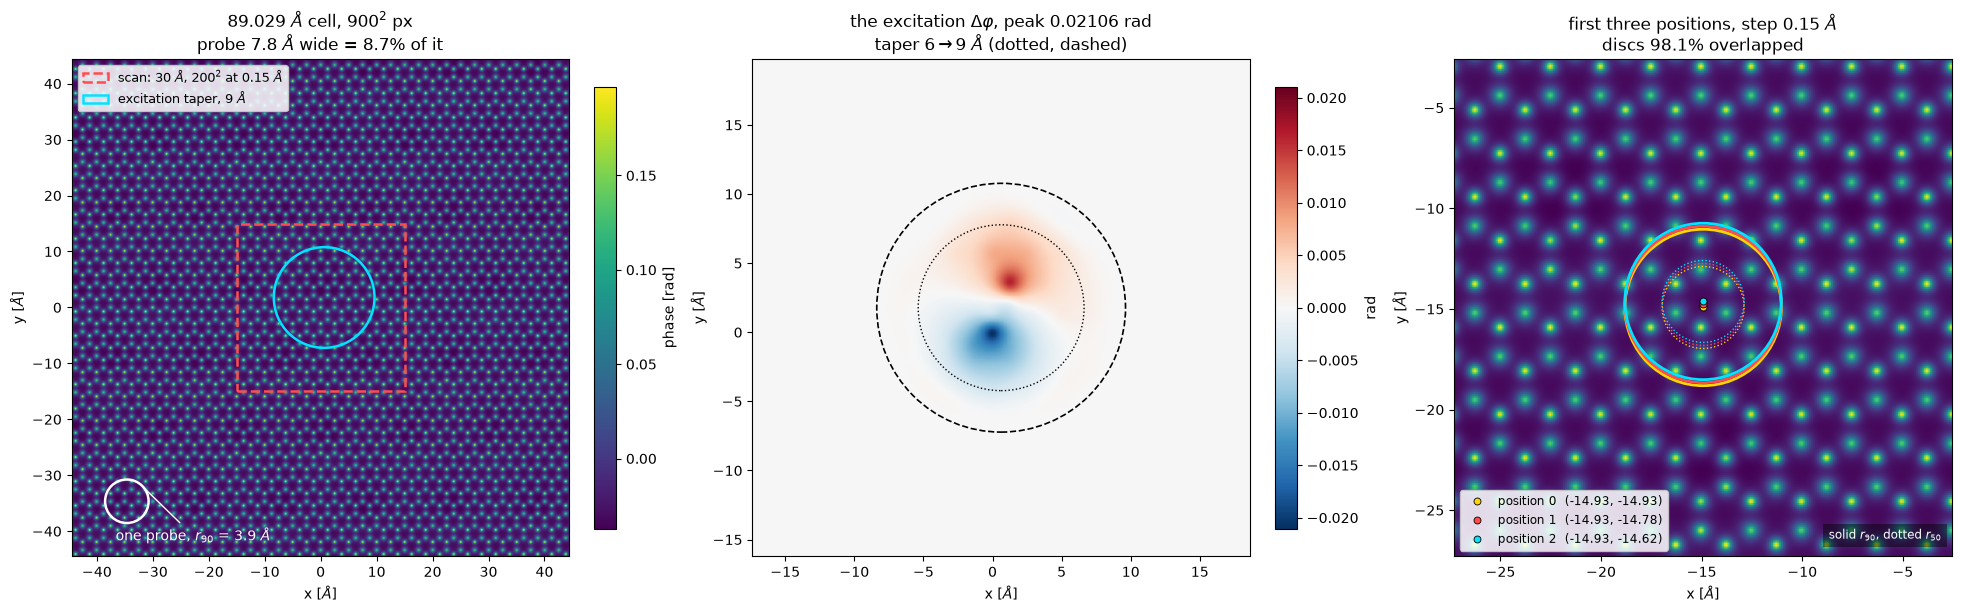

In [6]:
extent = [object_x_ang[0], object_x_ang[-1]] * 2
fig, axes = plt.subplots(1, 3, figsize=(19.5, 6.2), constrained_layout=True)

ax = axes[0]
im = ax.imshow(phase_base.T, extent=extent, origin="lower", cmap="viridis")
half = SCAN_EXTENT_ANG / 2
ax.add_patch(Rectangle((-half, -half), 2 * half, 2 * half, fill=False,
                       ec="#ff4d4d", lw=1.8, ls="--",
                       label=f"scan: {SCAN_EXTENT_ANG:.0f} $\\AA$, "
                             f"{N_SCAN}$^2$ at {SCAN_STEP_ANG} $\\AA$"))
ax.add_patch(Circle(blob_centre, TAPER_OUTER_ANG, fill=False, ec="#00e5ff", lw=1.8,
                    label=f"excitation taper, {TAPER_OUTER_ANG:.0f} $\\AA$"))
_pc = -0.78 * object_x_ang[-1]
ax.add_patch(Circle((_pc, _pc), r90, fill=False, ec="w", lw=1.8))
ax.annotate(f"one probe, $r_{{90}}$ = {r90:.1f} $\\AA$",
            xy=(_pc + r90 * 0.7, _pc + r90 * 0.7), xytext=(_pc - 2, _pc - 7),
            color="w", fontsize=10, arrowprops=dict(arrowstyle="-", color="w", lw=1.0))
ax.set_title(f"{CELL_EXTENT_ANG} $\\AA$ cell, {N_OBJECT_PX}$^2$ px\n"
             f"probe {2*r90:.1f} $\\AA$ wide = {2*r90/CELL_EXTENT_ANG:.1%} of it")
ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
ax.legend(loc="upper left", fontsize=9, framealpha=0.85)
fig.colorbar(im, ax=ax, shrink=0.8, label="phase [rad]")

ax = axes[1]
lim = float(np.abs(delta_phi_true).max())
im = ax.imshow(delta_phi_true.T, extent=extent, origin="lower", cmap="RdBu_r",
               vmin=-lim, vmax=lim)
ax.add_patch(Circle(blob_centre, TAPER_INNER_ANG, fill=False, ec="k", lw=1.0, ls=":"))
ax.add_patch(Circle(blob_centre, TAPER_OUTER_ANG, fill=False, ec="k", lw=1.2, ls="--"))
ax.set_xlim(blob_centre[0] - 18, blob_centre[0] + 18)
ax.set_ylim(blob_centre[1] - 18, blob_centre[1] + 18)
ax.set_title(f"the excitation $\\Delta\\varphi$, peak {lim:.5f} rad\n"
             f"taper {TAPER_INNER_ANG:.0f}$\\to${TAPER_OUTER_ANG:.0f} $\\AA$ (dotted, dashed)")
ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
fig.colorbar(im, ax=ax, shrink=0.8, label="rad")

# the first three scan positions with the probe drawn to scale
ax = axes[2]
zc, zr = scan_object[1], r90 * 3.2
inside = (object_x_ang > zc[0] - zr) & (object_x_ang < zc[0] + zr)
ax.imshow(phase_base[np.ix_(inside, inside)].T, origin="lower", cmap="viridis",
          extent=[object_x_ang[inside][0], object_x_ang[inside][-1]] * 2)
for i, colour in enumerate(["#ffd400", "#ff4d4d", "#00e5ff"]):
    ax.add_patch(Circle(scan_object[i], r90, fill=False, ec=colour, lw=2.0))
    ax.add_patch(Circle(scan_object[i], r50, fill=False, ec=colour, lw=1.0, ls=":"))
    ax.plot(*scan_object[i], "o", ms=5, color=colour, mec="k", mew=0.6,
            label=f"position {i}  ({scan_object[i][0]:+.2f}, {scan_object[i][1]:+.2f})")
ax.set_title(f"first three positions, step {SCAN_STEP_ANG} $\\AA$\n"
             f"discs {100*(1-SCAN_STEP_ANG/(2*r90)):.1f}% overlapped")
ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
ax.legend(loc="lower left", fontsize=8.5, framealpha=0.85)
ax.text(0.98, 0.03, "solid $r_{90}$, dotted $r_{50}$", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8.5, color="w",
        bbox=dict(fc="k", alpha=0.45, ec="none"))
plt.show()

### The interlacing

`mask[i, j] = (i + j) % 2 == 0`: light-on on the diagonal of every $2\times2$ cell,
light-off on the anti-diagonal. Each position carries **one** exposure, so there is no
position at which both states were measured - which is why nothing downstream may
subtract one state from the other pointwise, and why notebook 01 has to build two
separate scans instead.

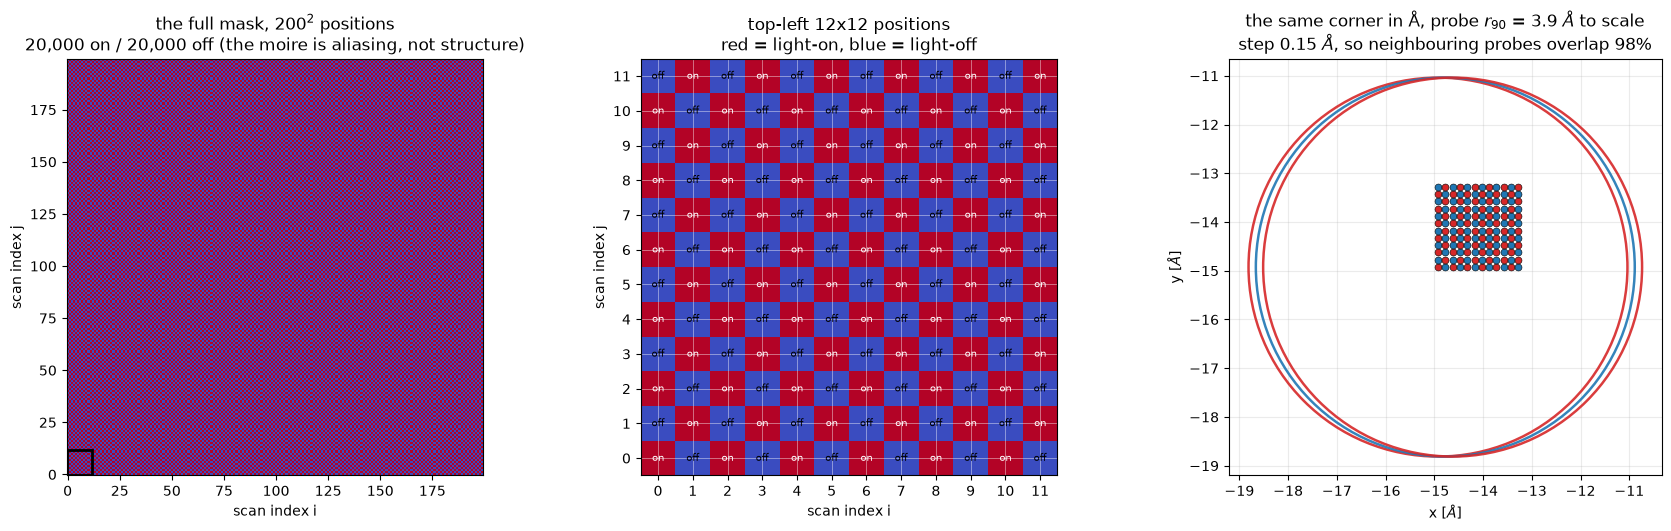

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2), constrained_layout=True)
ZOOM = 12

ax = axes[0]
ax.imshow(scan_mask.T, origin="lower", cmap="coolwarm", interpolation="nearest",
          extent=[-0.5, N_SCAN - 0.5, -0.5, N_SCAN - 0.5])
ax.add_patch(Rectangle((-0.5, -0.5), ZOOM, ZOOM, fill=False, ec="k", lw=2.0))
ax.set_title(f"the full mask, {N_SCAN}$^2$ positions\n"
             f"{scan_mask.sum():,} on / {scan_mask.size - scan_mask.sum():,} off "
             f"(the moire is aliasing, not structure)")
ax.set_xlabel("scan index i"); ax.set_ylabel("scan index j")

ax = axes[1]
sub = scan_mask[:ZOOM, :ZOOM]
ax.imshow(sub.T, origin="lower", cmap="coolwarm", interpolation="nearest",
          extent=[-0.5, ZOOM - 0.5, -0.5, ZOOM - 0.5], vmin=0, vmax=1)
for i in range(ZOOM):
    for j in range(ZOOM):
        ax.text(i, j, "on" if sub[i, j] else "off", ha="center", va="center",
                fontsize=7.5, color="w" if sub[i, j] else "k")
ax.set_xticks(range(ZOOM)); ax.set_yticks(range(ZOOM))
ax.grid(which="major", color="w", lw=0.6, alpha=0.5)
ax.set_title(f"top-left {ZOOM}x{ZOOM} positions\n"
             "red = light-on, blue = light-off")
ax.set_xlabel("scan index i"); ax.set_ylabel("scan index j")

# the same corner in physical units, with the probe drawn to scale
ax = axes[2]
for i in range(ZOOM):
    for j in range(ZOOM):
        on = bool(scan_mask[i, j])
        ax.plot(scan_axis[i], scan_axis[j], "o", ms=5,
                color="#d62728" if on else "#1f77b4", mec="k", mew=0.4, zorder=3)
for (i, j), colour in (((0, 0), "#d62728"), ((1, 0), "#1f77b4"), ((2, 0), "#d62728")):
    ax.add_patch(Circle((scan_axis[i], scan_axis[j]), r90, fill=False, ec=colour,
                        lw=1.8, alpha=0.9, zorder=2))
ax.set_aspect("equal")
ax.set_title(f"the same corner in \u00c5, probe $r_{{90}}$ = {r90:.1f} $\\AA$ to scale\n"
             f"step {SCAN_STEP_ANG} $\\AA$, so neighbouring probes overlap "
             f"{100*(1-SCAN_STEP_ANG/(2*r90)):.0f}%")
ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
ax.grid(alpha=0.25)
plt.show()

## Simulate, interlace, dose

Both states are simulated at every position and interlaced afterwards. The checkerboard
is `(i + j) % 2 == 0 -> 1`, which is the convention `method_wrappers` expects: mask 1 is
light-on, mask 0 is light-off. Each position holds **one** exposure, which is the whole
point of the acquisition - there is no position at which both states were measured, so
nothing downstream may subtract one from the other pointwise.

The un-binned stack is never held in full: at $384^2$ per position, 33,124 of them would
be 19.5 GB, so abTEM is called in chunks and each chunk is cropped and binned on the GPU
before it is stored.

In [8]:
print(f"=== {N_SCAN} x {N_SCAN} = {N_SCAN**2:,} positions ===")
print(f"  output cube: {N_SCAN**2 * n_detector_binned**2 * 4 / 1e9:.2f} GB float32 per dose")

cube_base = simulate(potential_base, scan_abtem, "base   ")
cube_excited = simulate(potential_excited, scan_abtem, "excited")
cube_base = cube_base.reshape(N_SCAN, N_SCAN, n_detector_binned, n_detector_binned)
cube_excited = cube_excited.reshape(N_SCAN, N_SCAN, n_detector_binned, n_detector_binned)

rel = np.abs(cube_excited - cube_base).max() / cube_base.max()
print(f"  collected intensity per pattern   : {cube_base[N_SCAN//2, N_SCAN//2].sum():.4f}")
print(f"  largest excitation-induced change : {rel:.3e} of the brightest pixel")

=== 200 x 200 = 40,000 positions ===
  output cube: 5.90 GB float32 per dose


    base      2.6%  (  0.5 s)


    base      5.1%  (  0.9 s)


    base      7.7%  (  1.3 s)


    base     10.2%  (  1.8 s)


    base     12.8%  (  2.2 s)


... (70 outputs left out)

    excited  94.7%  ( 15.5 s)


    excited  97.3%  ( 15.9 s)


    excited  99.8%  ( 16.4 s)
    excited 100.0%  ( 16.4 s)
  excited done: 40,000 positions in 16.4 s


  collected intensity per pattern   : 0.9998
  largest excitation-induced change : 1.776e-02 of the brightest pixel


### One diffraction pattern at each dose

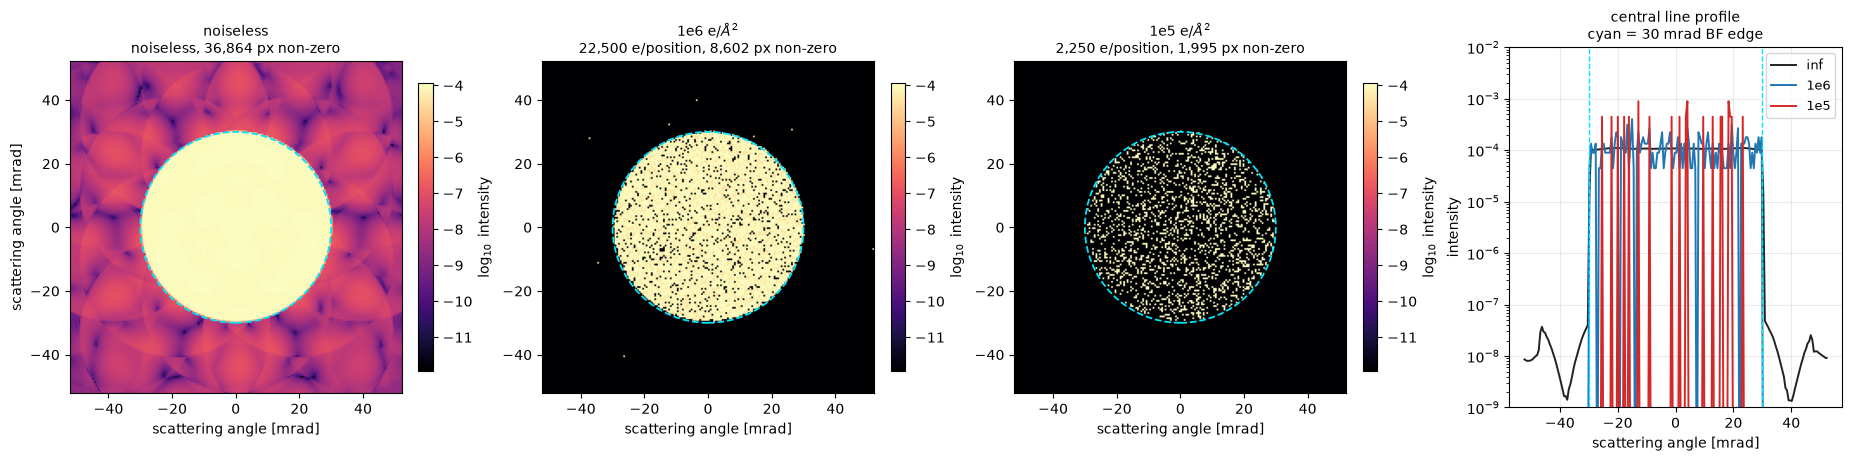

In [9]:
fig, axes = plt.subplots(1, len(DOSES) + 1, figsize=(4.6 * (len(DOSES) + 1), 4.5),
                         constrained_layout=True)
q_axis = (np.arange(n_detector_binned) - n_detector_binned / 2 + 0.5) * binned_pitch_mrad
det_extent = [q_axis[0], q_axis[-1]] * 2

pattern = cube_excited[N_SCAN // 2, N_SCAN // 2].astype(np.float64)
pattern /= pattern.sum()
by_dose = {}
for key, dose in DOSES.items():
    if dose is None:
        by_dose[key] = pattern.copy()
    else:
        counts = np.random.default_rng().poisson(
            pattern * dose * SCAN_STEP_ANG ** 2).astype(np.float64)
        by_dose[key] = counts / max(counts.sum(), 1.0)
floor = by_dose["inf"][by_dose["inf"] > 0].min()
vmin, vmax = np.log10(floor), np.log10(by_dose["inf"].max())

for col, (key, dose) in enumerate(DOSES.items()):
    ax = axes[col]
    im = ax.imshow(np.log10(np.maximum(by_dose[key], floor)).T, extent=det_extent,
                   origin="lower", cmap="magma", vmin=vmin, vmax=vmax)
    ax.add_patch(Circle((0, 0), PROBE_SEMIANGLE_MRAD, fill=False, ec="#00e5ff",
                        lw=1.3, ls="--"))
    e = "noiseless" if dose is None else f"{dose*SCAN_STEP_ANG**2:,.0f} e/position"
    ax.set_title(f"{'noiseless' if dose is None else key + ' e/$\\AA^2$'}\n{e}, "
                 f"{np.count_nonzero(by_dose[key]):,} px non-zero", fontsize=10)
    ax.set_xlabel("scattering angle [mrad]")
    if col == 0:
        ax.set_ylabel("scattering angle [mrad]")
    fig.colorbar(im, ax=ax, shrink=0.8, label="$\\log_{10}$ intensity")

ax = axes[-1]
mid = n_detector_binned // 2
for key, colour in zip(DOSES, ["#222222", "#1f77b4", "#d62728"]):
    ax.semilogy(q_axis, np.maximum(by_dose[key][:, mid], 1e-12), lw=1.4, color=colour,
                label=key)
for sign in (-1, 1):
    ax.axvline(sign * PROBE_SEMIANGLE_MRAD, color="#00e5ff", ls="--", lw=1.0)
ax.set_ylim(1e-9, 1e-2); ax.grid(alpha=0.25); ax.legend(fontsize=9)
ax.set_title("central line profile\ncyan = 30 mrad BF edge", fontsize=10)
ax.set_xlabel("scattering angle [mrad]"); ax.set_ylabel("intensity")
plt.show()

## Write

Metadata goes to **JSON**, one file, indent 2, meant to be opened and read. The only
binary files are the ground-truth phase images, which are $720^2$ floats each and cannot
be text, and the datacubes themselves.

In [10]:
scan_params = {
    "probe_energy": ACC_VOLTAGE_EV,
    "probe_semiangle": PROBE_SEMIANGLE_MRAD,
    "probe_defocus": PROBE_DEFOCUS_ANG,
    # method_wrappers' convention: the COARSE step, i.e. one de-interlaced channel.
    "scan_step": 2 * SCAN_STEP_ANG,
}

metadata = {
    "generated_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
    "generated_by": "00_generate_ideal_dataset.ipynb",
    "beam": {
        "accelerating_voltage_eV": ACC_VOLTAGE_EV,
        "wavelength_ang": round(wavelength_ang, 8),
        "convergence_semiangle_mrad": PROBE_SEMIANGLE_MRAD,
        "defocus_C10_ang": PROBE_DEFOCUS_ANG,
        "aberrations": "none beyond C10 - this is the ideal case",
    },
    "probe": {
        "r50_ang": round(float(r50), 4),
        "r90_ang": round(float(r90), 4),
        "r99_ang": round(float(r99), 4),
        "geometric_radius_alpha_C10_ang": round(PROBE_SEMIANGLE_MRAD * 1e-3 * PROBE_DEFOCUS_ANG, 4),
        "overlap_between_neighbours": round(float(1 - SCAN_STEP_ANG / (2 * r90)), 5),
        "bandwidth_inv_ang": round(2 * PROBE_SEMIANGLE_MRAD * 1e-3 / wavelength_ang, 5),
        "alias_free_step_ang": round(wavelength_ang / (4 * PROBE_SEMIANGLE_MRAD * 1e-3), 5),
    },
    "cell": {
        "extent_ang": CELL_EXTENT_ANG,
        "n_pixels": N_OBJECT_PX,
        "dx_ang": round(OBJECT_DX_ANG, 8),
        "edge_margin_ang": round(float(edge_margin), 4),
        "why": "L = 36.0193 * detector_bin puts ARINA's pitch on an exact integer bin",
    },
    "detector": {
        "model": "Dectris ARINA",
        "native_pitch_mrad": round(DETECTOR_PITCH_MRAD, 8),
        "bin": DETECTOR_BIN,
        "binned_pitch_mrad": round(binned_pitch_mrad, 8),
        "arina_pitch_mrad": ARINA_PITCH_MRAD,
        "bin_error": round(float(abs(binned_pitch_mrad / ARINA_PITCH_MRAD - 1)), 6),
        "n_pixels_native": n_detector_native,
        "n_pixels_binned": n_detector_binned,
        "collection_half_angle_mrad": round(crop_half_angle_mrad, 4),
        "antialias_cutoff_mrad": round(antialias_mrad, 4),
    },
    "scan": {
        "n_positions_per_side": N_SCAN,
        "n_positions": N_SCAN ** 2,
        "step_ang": SCAN_STEP_ANG,
        "extent_ang": SCAN_EXTENT_ANG,
        "span_ang": round(float(scan_span), 4),
        "axis_first_ang": round(float(scan_axis[0]), 5),
        "axis_last_ang": round(float(scan_axis[-1]), 5),
        "positions_rule": "axis = (arange(n) - (n-1)/2) * step; grid in 'ij' order, "
                          "component 0 = x, component 1 = y",
        "mask_rule": "mask[i, j] = (i + j) % 2 == 0 -> 1 = light-on, 0 = light-off",
        "scan_params_for_method_wrappers": scan_params,
    },
    "object": {
        "source_pickle": "hbn_bcenters_data/bcenters_base_excited_phases_wide_fov.pkl",
        "lattice_a_ang": A_HBN,
        "supercell": f"{N_HBN_CELLS}x{N_HBN_CELLS}",
        "axis_rule": "object_x_ang = (arange(n) - n//2) * dx_ang",
        "blob_centre_ang": [round(float(blob_centre[0]), 5), round(float(blob_centre[1]), 5)],
        "taper_inner_ang": TAPER_INNER_ANG,
        "taper_outer_ang": TAPER_OUTER_ANG,
        "base_phase_min_rad": round(float(phase_base.min()), 6),
        "base_phase_max_rad": round(float(phase_base.max()), 6),
        "delta_phi_min_rad": round(float(delta_phi_true.min()), 7),
        "delta_phi_max_rad": round(float(delta_phi_true.max()), 7),
        "delta_phi_peak_abs_rad": round(float(np.abs(delta_phi_true).max()), 7),
    },
    "doses_e_per_ang2": {k: v for k, v in DOSES.items()},
    "doses_e_per_position": {k: (None if v is None else round(v * SCAN_STEP_ANG ** 2, 1))
                             for k, v in DOSES.items()},
    "simulation": {
        "code": "abTEM " + abtem.__version__,
        "device": ABTEM_DEVICE,
        "slice_thickness_ang": SLICE_THICKNESS_ANG,
        "model": "single projected phase slice, probe.scan + CustomScan + PixelatedDetector",
        "phase_arrays_energy_note": "the stored hBN phases carry no energy metadata; the companion notebook 04 divides them by sigma(60 keV) and is annotated 'if acc is 60e3', so they are used here at the energy they were computed for",
        "rng_seed": None,
        "rng_note": "unseeded - each run of 00 draws an independent noise "
                    "realisation, so these files are not byte-reproducible",
        "largest_excitation_change_rel": float(f"{rel:.4e}"),
    },
    "files": {
        "ideal_truth.npz": "phase_base, phase_excited, delta_phi_true, excitation_mask "
                           f"- each {N_OBJECT_PX}^2 float32 on the object grid",
        "ideal_{base,excited}_noiseless.npy":
            f"({N_SCAN}, {N_SCAN}, {n_detector_binned}, {n_detector_binned}) float32, "
            "each state on its own, normalised, no shot noise - apply dose on load",
        "ideal_merged_dose_<key>.npy": f"({N_SCAN}, {N_SCAN}, {n_detector_binned}, "
                                       f"{n_detector_binned}) float32, each pattern "
                                       "normalised to sum 1",
    },
}

with open(DATA_DIR / "ideal_geometry.json", "w") as handle:
    json.dump(metadata, handle, indent=2)
print("wrote ideal_geometry.json")

np.savez_compressed(
    DATA_DIR / "ideal_truth.npz",
    phase_base=phase_base.astype(np.float32),
    phase_excited=phase_excited.astype(np.float32),
    delta_phi_true=delta_phi_true.astype(np.float32),
    excitation_mask=excitation_mask.astype(np.float32),
)
print(f"wrote ideal_truth.npz "
      f"({(DATA_DIR / 'ideal_truth.npz').stat().st_size/1e6:.1f} MB)")

# The two states on their own, noiseless. 01 and 03 both need them -- 03 to build the
# base / excited / interlaced comparison, 01 as the sequential two-scan experiment -- and
# both were re-simulating them because only the merged cube was ever stored. Saved
# noiseless because the dose is applied at load time, so any dose can be drawn from these.
for name, cube in (("base", cube_base), ("excited", cube_excited)):
    path = DATA_DIR / f"ideal_{name}_noiseless.npy"
    out = cube.astype(np.float32).copy()
    out /= out.sum(axis=(-2, -1), keepdims=True)
    np.save(path, out)
    print(f"  {path.name:34s} {path.stat().st_size/1e9:5.2f} GB")
    del out

for key, dose in DOSES.items():
    merged = merge_and_dose(cube_base, cube_excited, scan_mask, dose)
    path = DATA_DIR / f"ideal_merged_dose_{key}.npy"
    np.save(path, merged)
    print(f"  {path.name:34s} {path.stat().st_size/1e9:5.2f} GB")
    del merged

wrote ideal_geometry.json
wrote ideal_truth.npz (6.1 MB)


  ideal_base_noiseless.npy            5.90 GB


  ideal_excited_noiseless.npy         5.90 GB


  ideal_merged_dose_inf.npy           5.90 GB


  ideal_merged_dose_1e6.npy           5.90 GB


  ideal_merged_dose_1e5.npy           5.90 GB


## Check, with quanTEM's own virtual imaging

The bright- and dark-field images are formed by `Dataset4dstem.get_virtual_image`, with
the BF disc taken from `fit_probe_circle` on the mean diffraction pattern rather than
assumed. An earlier version of this notebook summed a hand-written $\pm20$ pixel square
box, which is neither the right shape nor the right size - the BF disc has a radius of
about 55 binned pixels.

fitted BF disc: centre (96.00, 96.00) px, radius 54.80 px = 29.95 mrad (aperture is 30.0 mrad)


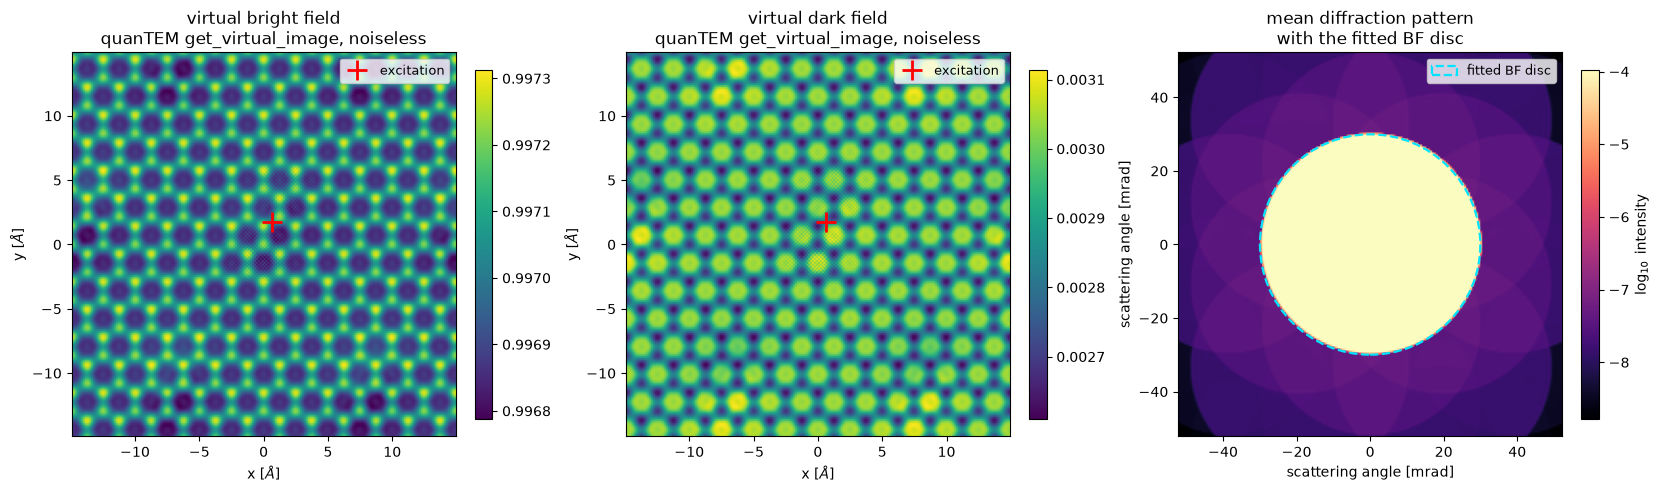


cube (200, 200, 192, 192), pattern sums 1.00000 .. 1.00000
BF disc holds ~9,435 px of 36,864
  dose 1e6: 22,500 e/position -> 2.38 e per BF pixel
  dose 1e5: 2,250 e/position -> 0.24 e per BF pixel


In [11]:
merged = np.load(DATA_DIR / "ideal_merged_dose_inf.npy")
dset = Dataset4dstem.from_array(
    merged, name="ideal",
    sampling=(SCAN_STEP_ANG, SCAN_STEP_ANG, binned_pitch_mrad, binned_pitch_mrad),
    units=("A", "A", "mrad", "mrad"),
)
qy0, qx0, probe_R_px = fit_probe_circle(dset.dp_mean.array, show=False)
print(f"fitted BF disc: centre ({qy0:.2f}, {qx0:.2f}) px, radius {probe_R_px:.2f} px "
      f"= {probe_R_px * binned_pitch_mrad:.2f} mrad "
      f"(aperture is {PROBE_SEMIANGLE_MRAD} mrad)")

bf = dset.get_virtual_image(mode="circle", geometry=((qy0, qx0), probe_R_px),
                            name="bright_field", attach=False)
df = dset.get_virtual_image(
    mode="annular",
    geometry=((qy0, qx0), (probe_R_px, n_detector_binned / 2)),
    name="dark_field", attach=False)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), constrained_layout=True)
ext = [scan_axis[0], scan_axis[-1]] * 2
for ax, image, title in ((axes[0], bf.array, "virtual bright field"),
                         (axes[1], df.array, "virtual dark field")):
    im = ax.imshow(np.asarray(image).T, extent=ext, origin="lower")
    ax.plot(*blob_centre, "r+", ms=14, mew=2, label="excitation")
    ax.set_title(f"{title}\nquanTEM get_virtual_image, noiseless")
    ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
    ax.legend(loc="upper right", fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.82)

ax = axes[2]
dpm = np.asarray(dset.dp_mean.array)
im = ax.imshow(np.log10(np.maximum(dpm, dpm[dpm > 0].min())).T, origin="lower",
               extent=det_extent, cmap="magma")
ax.add_patch(Circle((0, 0), probe_R_px * binned_pitch_mrad, fill=False, ec="#00e5ff",
                    lw=1.6, ls="--", label="fitted BF disc"))
ax.set_title("mean diffraction pattern\nwith the fitted BF disc")
ax.set_xlabel("scattering angle [mrad]"); ax.set_ylabel("scattering angle [mrad]")
ax.legend(fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.82, label="$\\log_{10}$ intensity")
plt.show()

sums = merged[::7, ::7].sum(axis=(2, 3))
print(f"\ncube {merged.shape}, pattern sums {sums.min():.5f} .. {sums.max():.5f}")
n_bf_px = int(round(np.pi * probe_R_px ** 2))
print(f"BF disc holds ~{n_bf_px:,} px of {n_detector_binned**2:,}")
for key, dose in DOSES.items():
    if dose is not None:
        print(f"  dose {key:>3s}: {dose*SCAN_STEP_ANG**2:,.0f} e/position -> "
              f"{dose*SCAN_STEP_ANG**2/n_bf_px:.2f} e per BF pixel")
del merged, dset

## Summary

One configuration, one set of files:

* `data/ideal_geometry.json` - every number above, readable
* `data/ideal_truth.npz` - the four ground-truth phase images
* `data/ideal_merged_dose_{inf,1e6,1e5}.npy` - 4.88 GB each

Notebooks 01-05 read the JSON for their parameters and the `.npy` for their data, and
09 compares them against `ideal_truth.npz`.